In [4]:
!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

Defaulting to user installation because normal site-packages is not writeable


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [1]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

Current Working Directory:
C:\Users\dhars\OneDrive\Documents\ml\Netflix Trend Forecasting

Files in current directory:
['.ipynb_checkpoints', 'analysis.ipynb', 'Dataset.csv']


In [4]:
df = pd.read_csv("Dataset.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
print(df.shape)
df.head()

(8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 1.6 MB


In [7]:
missing = df.isnull().sum()

print("Missing Values:")
print(missing)

print("\nMissing Value Percentage:")
print((missing / len(df)) * 100)

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Missing Value Percentage:
show_id         0.0
type            0.0
title           0.0
director        0.0
country         0.0
date_added      0.0
release_year    0.0
rating          0.0
duration        0.0
listed_in       0.0
dtype: float64


In [8]:
df.describe(include='all')

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
count,8790,8790,8790,8790,8790,8790,8790.000000,8790,8790,8790
unique,8790,2,8787,4528,86,1713,NaN,14,220,513
top,s1,Movie,9-Feb,Not Given,United States,1/1/2020,NaN,TV-MA,1 Season,"Dramas, International Movies"
freq,1,6126,2,2588,3240,110,NaN,3205,1791,362
mean,NaN,NaN,NaN,NaN,NaN,NaN,2014.183163,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,8.825466,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN


type
Movie      6126
TV Show    2664
Name: count, dtype: int64


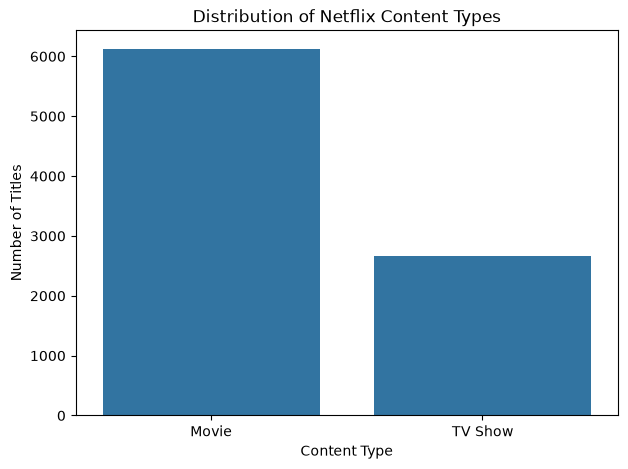

In [9]:
type_counts = df['type'].value_counts()

print(type_counts)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='type')

plt.title("Distribution of Netflix Content Types")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

In [17]:
df['date_added'] = pd.to_datetime(
    df['date_added'].str.strip(),
    errors='coerce'
)

print(df['date_added'].head())

AttributeError: Can only use .str accessor with string values, not datetime64

In [18]:
yearly_data = (
    df.dropna(subset=['date_added'])
      .groupby(df['date_added'].dt.year)
      .size()
)

print(yearly_data)

date_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1648
2019    2016
2020    1879
2021    1498
dtype: int64


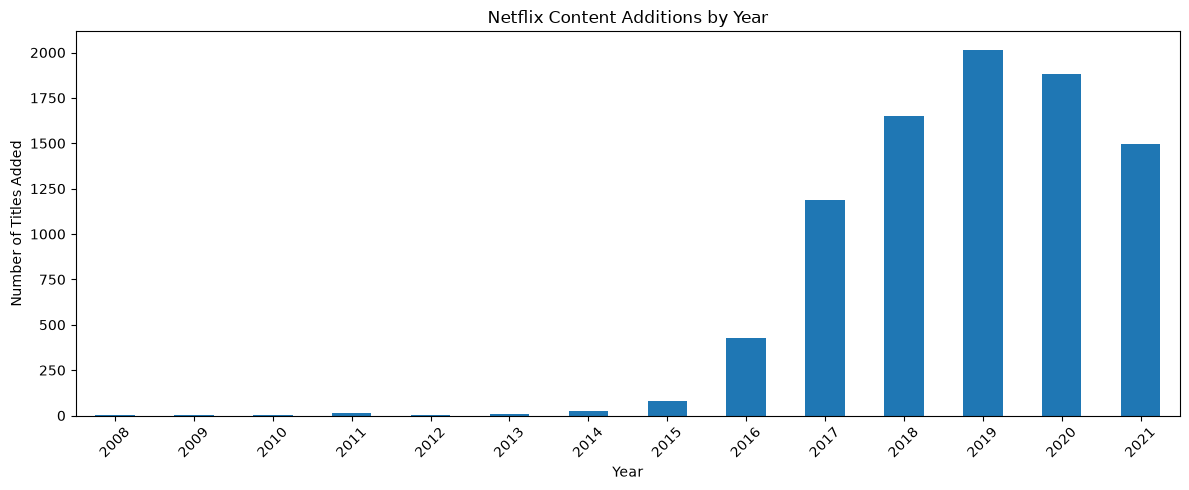

In [12]:
plt.figure(figsize=(12, 5))

yearly_data.plot(kind='bar')

plt.title("Netflix Content Additions by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles Added")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [19]:
df['date_added'].dt.strftime('%d-%m-%Y').head(10)

0    25-09-2021
1    24-09-2021
2    24-09-2021
3    22-09-2021
4    24-09-2021
5    24-09-2021
6    24-09-2021
7    01-05-2021
8    23-09-2021
9    01-05-2021
Name: date_added, dtype: str

In [20]:
clean_df = df.dropna(subset=['date_added']).copy()

monthly_data = (
    clean_df
    .set_index('date_added')
    .resample('MS')
    .size()
    .reset_index(name='titles_added')
)

print(monthly_data.head(15))

   date_added  titles_added
0  2008-01-01             1
1  2008-02-01             1
2  2008-03-01             0
3  2008-04-01             0
4  2008-05-01             0
5  2008-06-01             0
6  2008-07-01             0
7  2008-08-01             0
8  2008-09-01             0
9  2008-10-01             0
10 2008-11-01             0
11 2008-12-01             0
12 2009-01-01             0
13 2009-02-01             0
14 2009-03-01             0


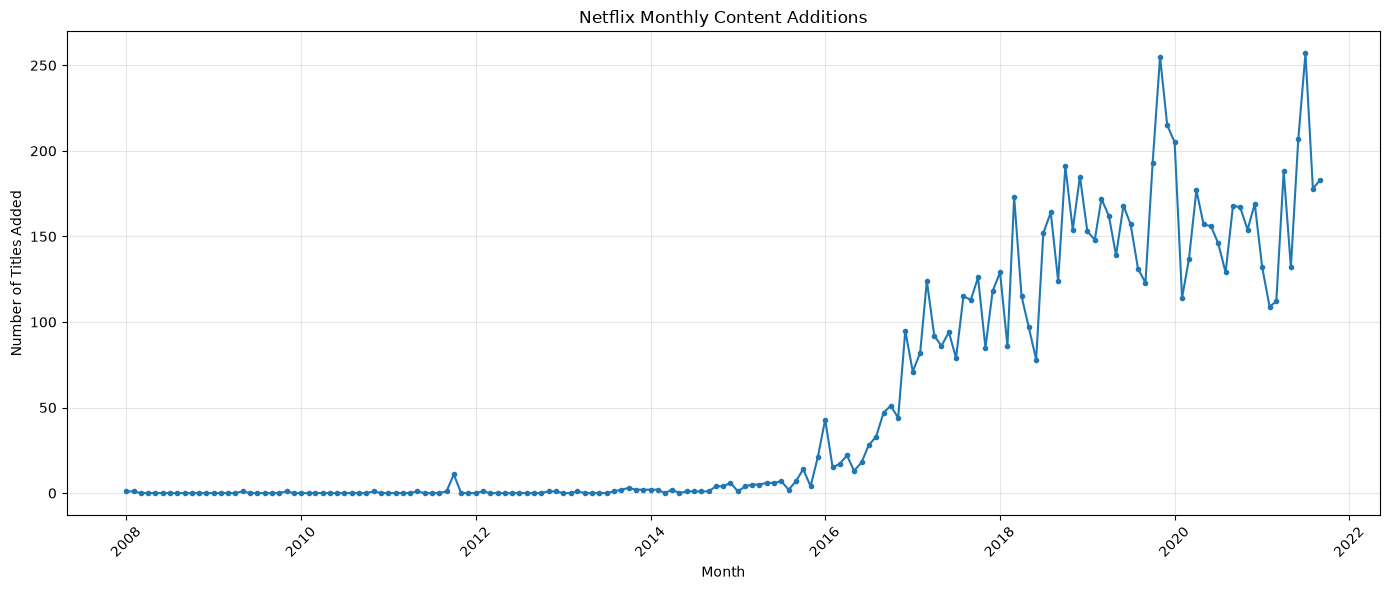

In [21]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_data['date_added'],
    monthly_data['titles_added'],
    marker='o',
    markersize=3
)

plt.title("Netflix Monthly Content Additions")
plt.xlabel("Month")
plt.ylabel("Number of Titles Added")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
monthly_data['month'] = monthly_data['date_added'].dt.month

monthly_data.head()

,date_added,titles_added,month
0,2008-01-01,1,1
1,2008-02-01,1,2
2,2008-03-01,0,3
3,2008-04-01,0,4
4,2008-05-01,0,5


In [23]:
monthly_avg = monthly_data.groupby('month')['titles_added'].mean()

print(monthly_avg)

month
1     52.642857
2     40.142857
3     52.928571
4     54.500000
5     45.142857
6     52.000000
7     59.071429
8     53.857143
9     54.928571
10    58.461538
11    54.230769
12    62.461538
Name: titles_added, dtype: float64


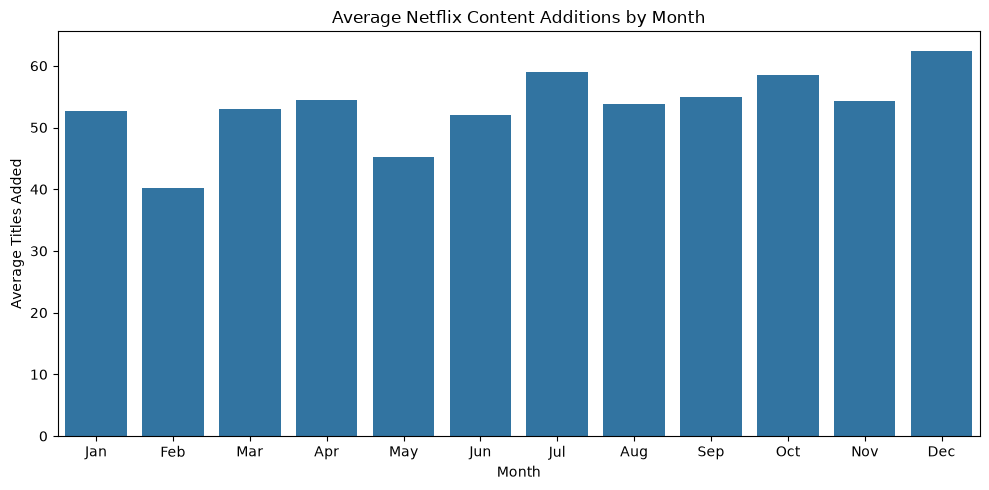

In [24]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_avg.index,
    y=monthly_avg.values
)

plt.title("Average Netflix Content Additions by Month")
plt.xlabel("Month")
plt.ylabel("Average Titles Added")

plt.xticks(
    range(12),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.tight_layout()
plt.show()

In [25]:
monthly_data['titles_added'].describe()

count    165.000000
mean      53.272727
std       71.597227
min        0.000000
25%        0.000000
50%        4.000000
75%      115.000000
max      257.000000
Name: titles_added, dtype: float64

In [26]:
from statsmodels.tsa.stattools import adfuller

In [27]:
result = adfuller(monthly_data['titles_added'])

print("ADF Statistic:", result[0])
print("p-value:", result[1])

print("\nCritical Values:")
for key, value in result[4].items():
    print(key, ":", value)

ADF Statistic: 0.49812990936632007
p-value: 0.9848161454372495

Critical Values:
1% : -3.474714913481481
5% : -2.881008708148148
10% : -2.5771508444444446


C:\Users\dhars\AppData\Local\Temp\ipykernel_30260\4086687270.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(monthly_data['titles_added'])


In [28]:
monthly_data['first_difference'] = (
    monthly_data['titles_added'].diff()
)

monthly_data.head(10)

,date_added,titles_added,month,first_difference
0,2008-01-01,1,1,NaN
1,2008-02-01,1,2,0.0
2,2008-03-01,0,3,-1.0
3,2008-04-01,0,4,0.0
4,2008-05-01,0,5,0.0
5,2008-06-01,0,6,0.0
6,2008-07-01,0,7,0.0
7,2008-08-01,0,8,0.0
8,2008-09-01,0,9,0.0
9,2008-10-01,0,10,0.0


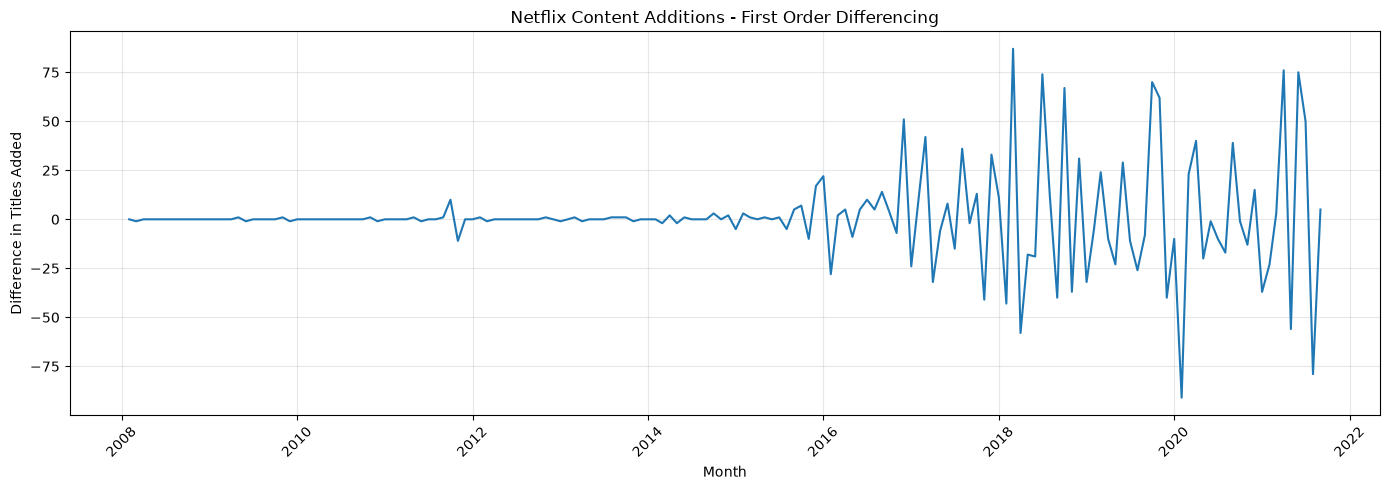

In [29]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_data['date_added'],
    monthly_data['first_difference']
)

plt.title("Netflix Content Additions - First Order Differencing")
plt.xlabel("Month")
plt.ylabel("Difference in Titles Added")

plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
diff_data = monthly_data['first_difference'].dropna()

result = adfuller(diff_data)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

print("\nCritical Values:")
for key, value in result[4].items():
    print(key, ":", value)

ADF Statistic: -2.170601918700148
p-value: 0.2170877153848459

Critical Values:
1% : -3.4750180242954167
5% : -2.8811408028842043
10% : -2.577221358046935


C:\Users\dhars\AppData\Local\Temp\ipykernel_30260\2947842542.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(diff_data)


In [31]:
monthly_data['second_difference'] = (
    monthly_data['first_difference'].diff()
)

In [32]:
second_diff = monthly_data['second_difference'].dropna()

result = adfuller(second_diff)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

print("\nCritical Values:")

for key, value in result[4].items():
    print(key, ":", value)

ADF Statistic: -8.706236393837466
p-value: 3.6937704132514396e-14

Critical Values:
1% : -3.4750180242954167
5% : -2.8811408028842043
10% : -2.577221358046935


C:\Users\dhars\AppData\Local\Temp\ipykernel_30260\1163561305.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(second_diff)


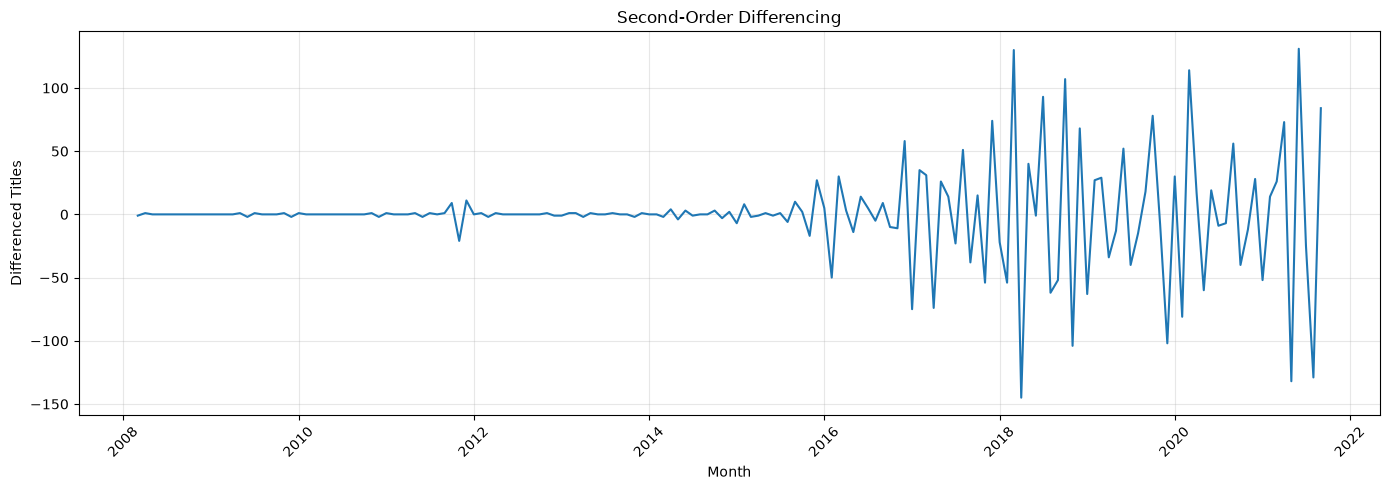

In [33]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_data['date_added'],
    monthly_data['second_difference']
)

plt.title("Second-Order Differencing")
plt.xlabel("Month")
plt.ylabel("Differenced Titles")

plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [35]:
second_diff = monthly_data['second_difference'].dropna()

<Figure size 1200x500 with 0 Axes>

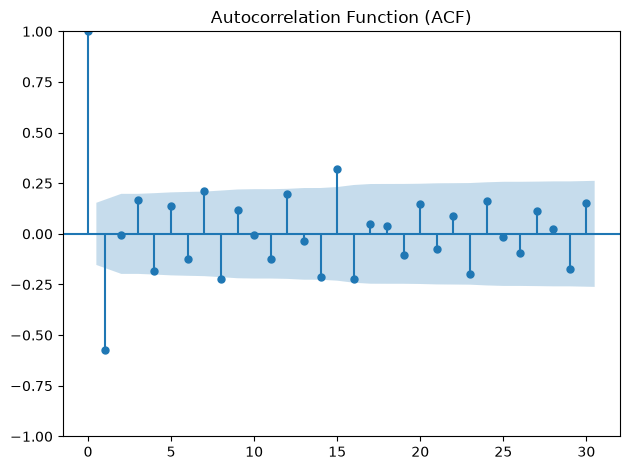

In [36]:
plt.figure(figsize=(12, 5))

plot_acf(second_diff, lags=30)

plt.title("Autocorrelation Function (ACF)")
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

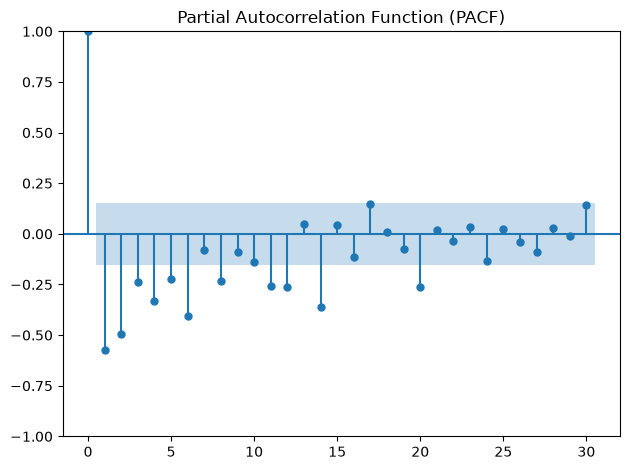

In [37]:
plt.figure(figsize=(12, 5))

plot_pacf(second_diff, lags=30, method='ywm')

plt.title("Partial Autocorrelation Function (PACF)")
plt.tight_layout()
plt.show()

In [38]:
# Original monthly time series
ts = monthly_data.set_index('date_added')['titles_added']

# Calculate split point
split_index = int(len(ts) * 0.8)

# Split chronologically
train = ts.iloc[:split_index]
test = ts.iloc[split_index:]

print("Training records:", len(train))
print("Testing records:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training records: 132
Testing records: 33

Training period:
2008-01-01 00:00:00 to 2018-12-01 00:00:00

Testing period:
2019-01-01 00:00:00 to 2021-09-01 00:00:00


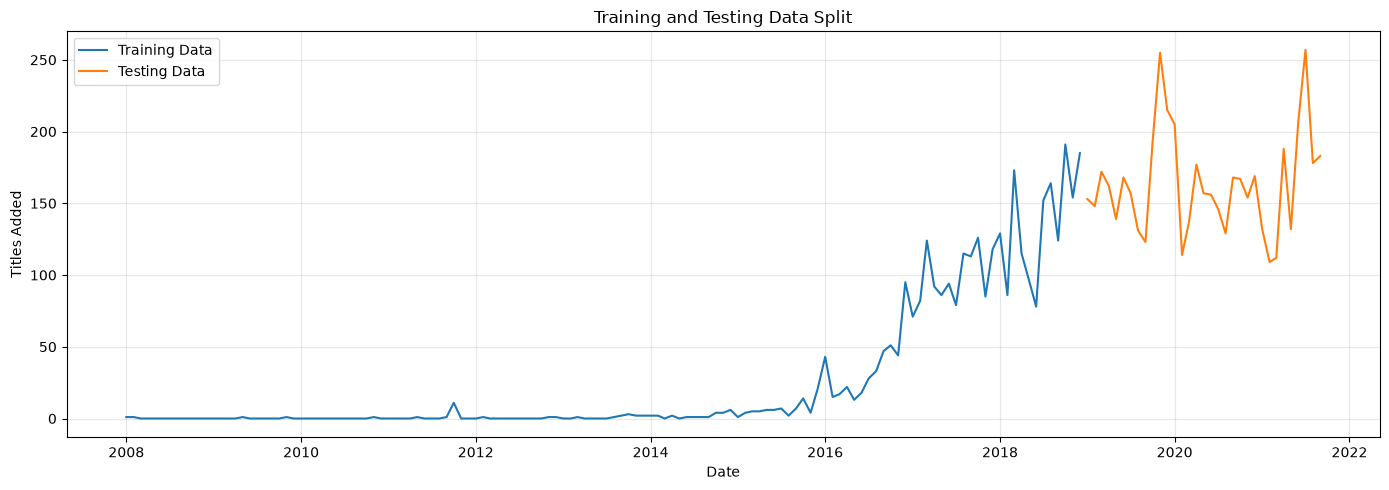

In [39]:
plt.figure(figsize=(14, 5))

plt.plot(train, label='Training Data')
plt.plot(test, label='Testing Data')

plt.title("Training and Testing Data Split")
plt.xlabel("Date")
plt.ylabel("Titles Added")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
from statsmodels.tsa.arima.model import ARIMA

In [41]:
model = ARIMA(train, order=(1, 2, 1))
model_fit = model.fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:           titles_added   No. Observations:                  132
Model:                 ARIMA(1, 2, 1)   Log Likelihood                -540.081
Date:                Wed, 04 Nov 2026   AIC                           1086.162
Time:                        22:52:25   BIC                           1094.764
Sample:                    01-01-2008   HQIC                          1089.657
                         - 12-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5238      0.036    -14.520      0.000      -0.595      -0.453
ma.L1         -0.9737      0.020    -49.456      0.000      -1.012      -0.935
sigma2       230.3324     13.976     16.480      0.0

C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [42]:
predictions = model_fit.forecast(steps=len(test))
print(predictions.head())

2019-01-01    173.353246
2019-02-01    184.046649
2019-03-01    183.037341
2019-04-01    188.158404
2019-05-01    190.068122
Freq: MS, Name: predicted_mean, dtype: float64


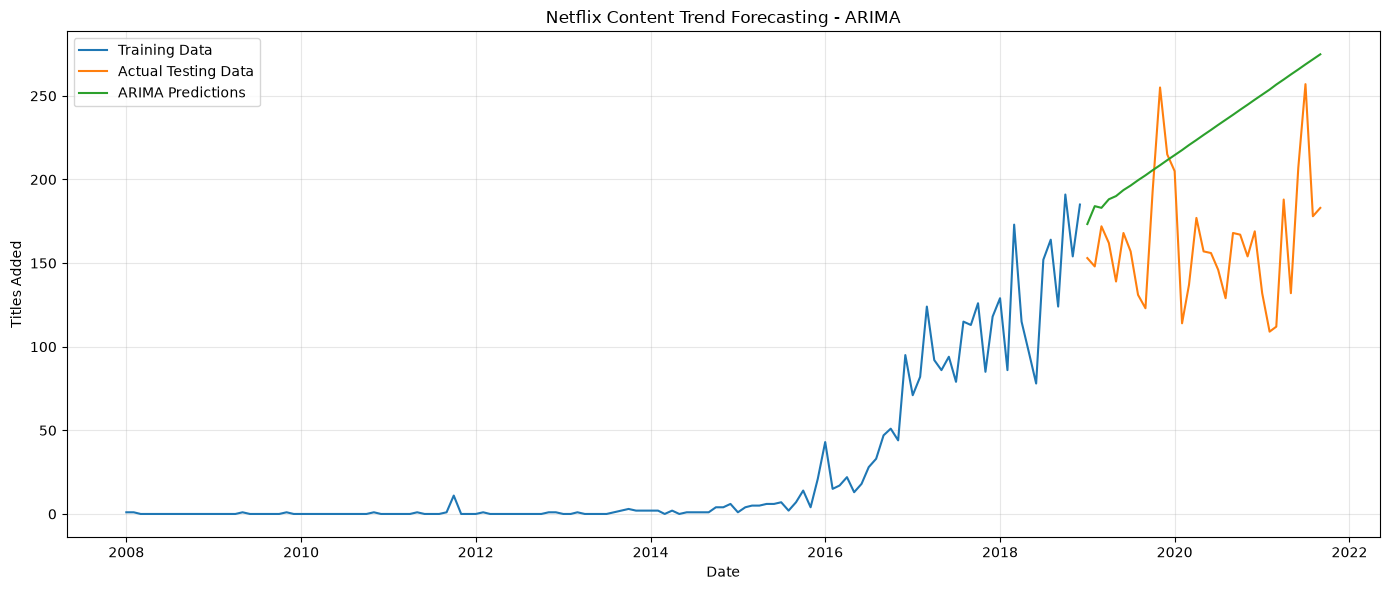

In [43]:
plt.figure(figsize=(14, 6))

plt.plot(train, label='Training Data')
plt.plot(test, label='Actual Testing Data')
plt.plot(predictions, label='ARIMA Predictions')

plt.title("Netflix Content Trend Forecasting - ARIMA")
plt.xlabel("Date")
plt.ylabel("Titles Added")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test, predictions)

rmse = np.sqrt(mean_squared_error(test, predictions))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 66.11322048073264
RMSE: 76.64767262964322


In [45]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def evaluate_arima(order):

    model = ARIMA(train, order=order)
    fitted_model = model.fit()

    forecast = fitted_model.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)

    rmse = np.sqrt(mean_squared_error(test, forecast))

    return mae, rmse

In [46]:
orders = [
    (0, 1, 1),
    (1, 1, 1),
    (0, 2, 1),
    (1, 2, 1)
]

results = []

for order in orders:

    mae, rmse = evaluate_arima(order)

    results.append({
        'Model': str(order),
        'MAE': mae,
        'RMSE': rmse
    })

comparison = pd.DataFrame(results)

print(comparison.sort_values('RMSE'))

C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480:

       Model        MAE       RMSE
0  (0, 1, 1)  28.100105  36.091664
1  (1, 1, 1)  28.759333  36.470490
2  (0, 2, 1)  51.519010  58.612082
3  (1, 2, 1)  66.113220  76.647673


C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [47]:
best_model = ARIMA(train, order=(0, 1, 1))

best_fit = best_model.fit()

print(best_fit.summary())

                               SARIMAX Results                                
Dep. Variable:           titles_added   No. Observations:                  132
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -538.805
Date:                Wed, 04 Nov 2026   AIC                           1081.610
Time:                        22:57:16   BIC                           1087.361
Sample:                    01-01-2008   HQIC                          1083.947
                         - 12-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5590      0.047    -11.989      0.000      -0.650      -0.468
sigma2       218.1726     12.243     17.820      0.000     194.176     242.169
Ljung-Box (L1) (Q):                   3.21   Jarque-

C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [48]:
best_predictions = best_fit.forecast(steps=len(test))

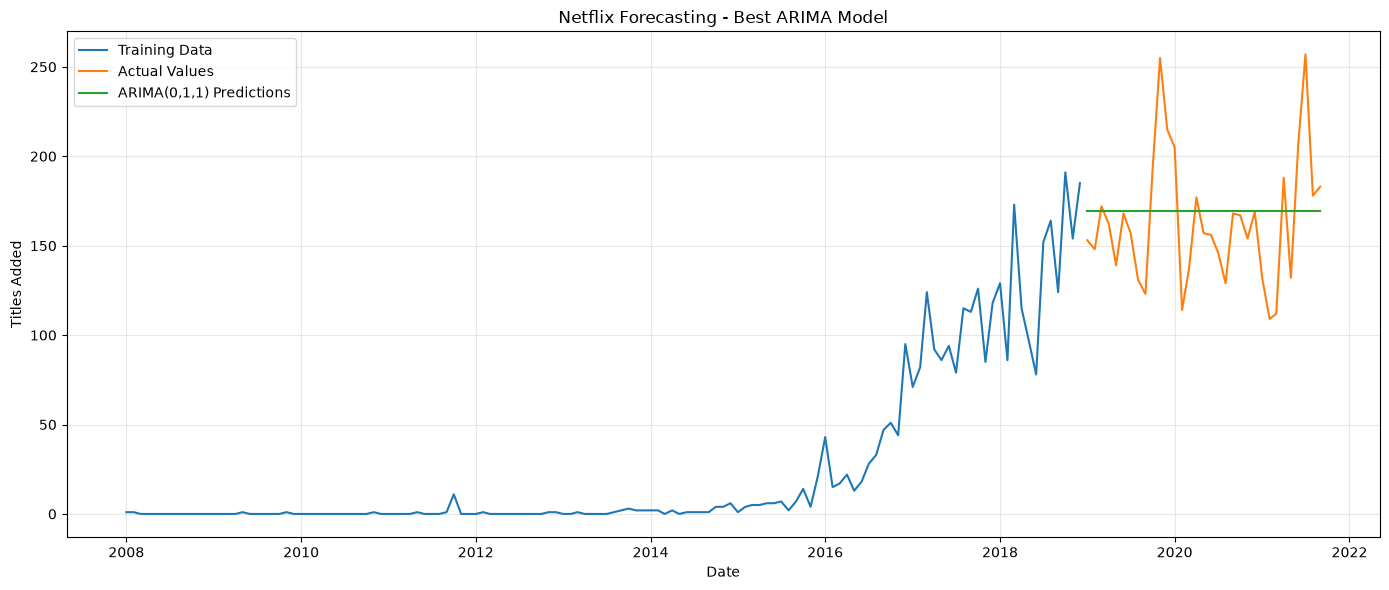

In [49]:
plt.figure(figsize=(14, 6))

plt.plot(train, label='Training Data')
plt.plot(test, label='Actual Values')
plt.plot(best_predictions, label='ARIMA(0,1,1) Predictions')

plt.title("Netflix Forecasting - Best ARIMA Model")
plt.xlabel("Date")
plt.ylabel("Titles Added")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

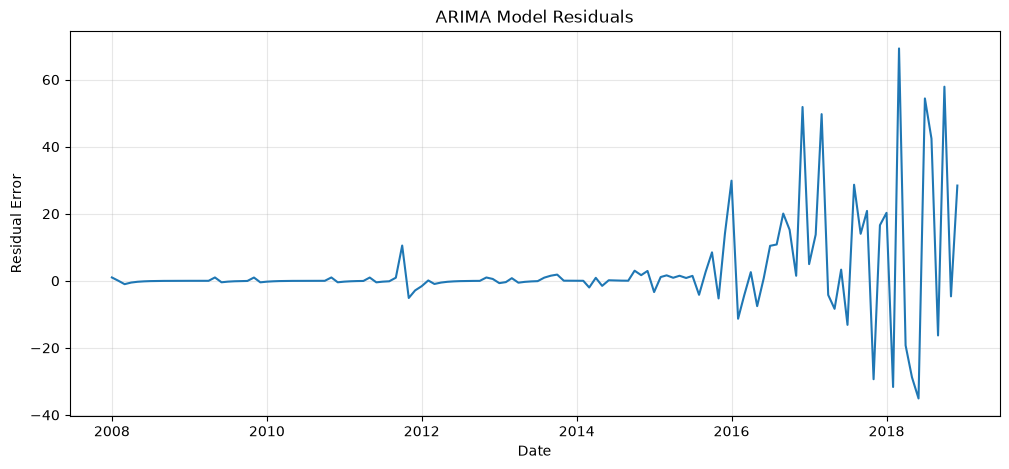

In [50]:
residuals = best_fit.resid

plt.figure(figsize=(12, 5))

plt.plot(residuals)

plt.title("ARIMA Model Residuals")
plt.xlabel("Date")
plt.ylabel("Residual Error")

plt.grid(alpha=0.3)
plt.show()

In [51]:
from statsmodels.stats.diagnostic import acorr_ljungbox

print(acorr_ljungbox(
    residuals,
    lags=[10],
    return_df=True
))

     lb_stat  lb_pvalue
10  31.17137    0.00055


In [52]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [53]:
seasonal_model = SARIMAX(
    train,
    order=(0, 1, 1),
    seasonal_order=(1, 0, 1, 12)
)

seasonal_fit = seasonal_model.fit(disp=False)

print(seasonal_fit.summary())

C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                       titles_added   No. Observations:                  132
Model:             SARIMAX(0, 1, 1)x(1, 0, 1, 12)   Log Likelihood                -526.638
Date:                            Wed, 04 Nov 2026   AIC                           1061.275
Time:                                    22:58:56   BIC                           1072.776
Sample:                                01-01-2008   HQIC                          1065.949
                                     - 12-01-2018                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.6054      0.037    -16.421      0.000      -0.678      -0.533
ar.S.L12       0.7539      0.209   

In [54]:
seasonal_predictions = seasonal_fit.forecast(
    steps=len(test)
)

In [55]:
mae = mean_absolute_error(test, seasonal_predictions)

rmse = np.sqrt(
    mean_squared_error(test, seasonal_predictions)
)

print("SARIMA MAE:", mae)
print("SARIMA RMSE:", rmse)

SARIMA MAE: 53.7359943232293
SARIMA RMSE: 64.15606533313154


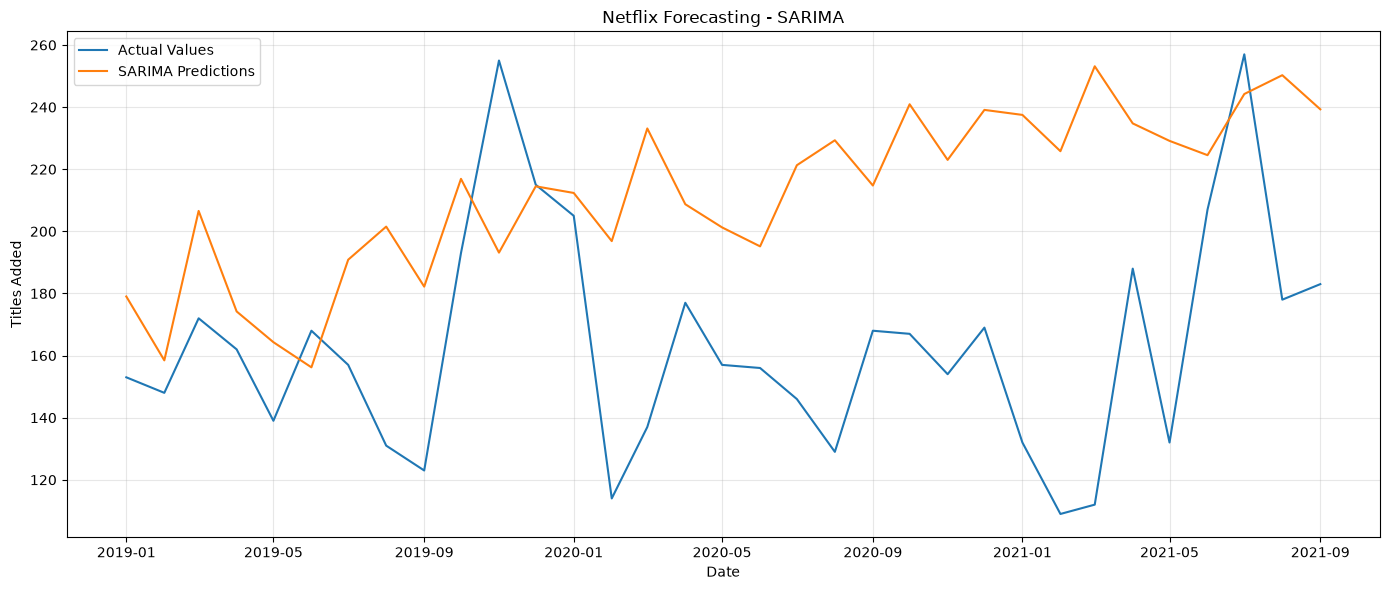

In [56]:
plt.figure(figsize=(14, 6))

plt.plot(test, label='Actual Values')
plt.plot(
    seasonal_predictions,
    label='SARIMA Predictions'
)

plt.title("Netflix Forecasting - SARIMA")
plt.xlabel("Date")
plt.ylabel("Titles Added")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [57]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [58]:
holt_model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal=None,
    initialization_method='estimated'
)

holt_fit = holt_model.fit()

print(holt_fit.summary())

                       ExponentialSmoothing Model Results                       
Dep. Variable:             titles_added   No. Observations:                  132
Model:             ExponentialSmoothing   SSE                          25443.376
Optimized:                         True   AIC                            702.506
Trend:                         Additive   BIC                            714.037
Seasonal:                          None   AICC                           703.178
Seasonal Periods:                  None   Date:                 Wed, 04 Nov 2026
Box-Cox:                          False   Time:                         23:00:12
Box-Cox Coeff.:                    None                                         
                       coeff                 code              optimized      
------------------------------------------------------------------------------
smoothing_level            0.2789712                alpha                 True
smoothing_trend            0.08540

C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [59]:
holt_predictions = holt_fit.forecast(len(test))

In [60]:
holt_mae = mean_absolute_error(test, holt_predictions)

holt_rmse = np.sqrt(
    mean_squared_error(test, holt_predictions)
)

print("Holt MAE:", holt_mae)
print("Holt RMSE:", holt_rmse)

Holt MAE: 87.1493602040341
Holt RMSE: 101.01544460807538


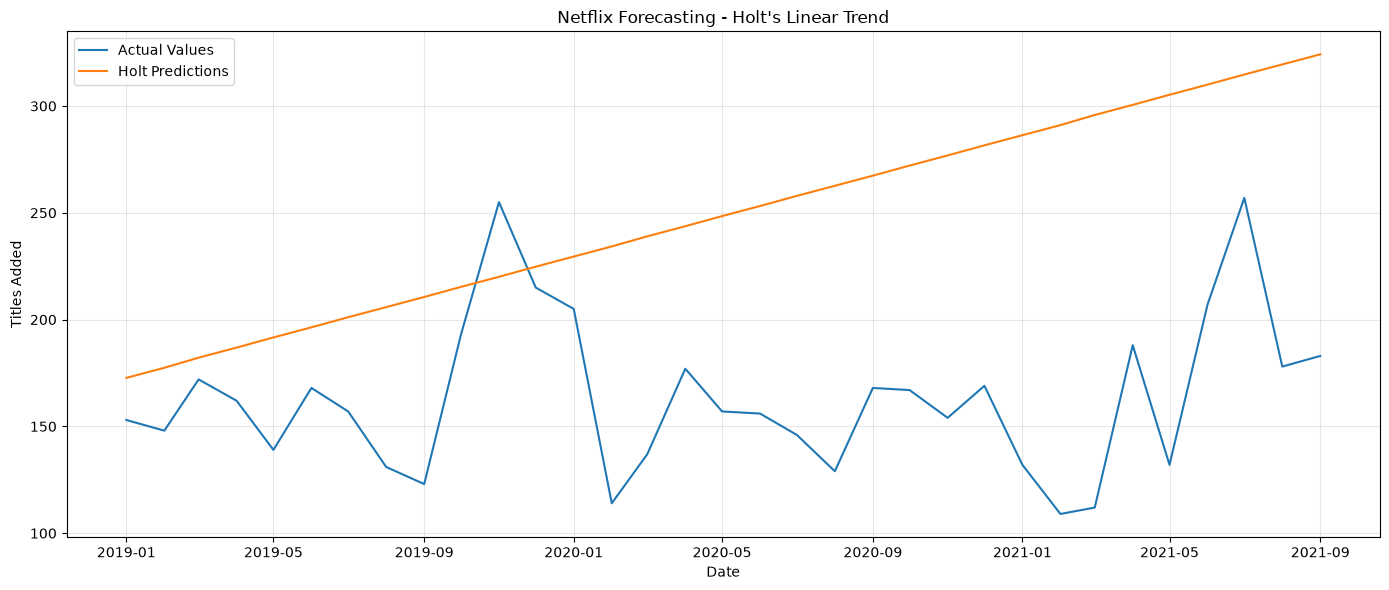

In [61]:
plt.figure(figsize=(14, 6))

plt.plot(test, label='Actual Values')
plt.plot(holt_predictions, label='Holt Predictions')

plt.title("Netflix Forecasting - Holt's Linear Trend")
plt.xlabel("Date")
plt.ylabel("Titles Added")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
final_results = pd.DataFrame({
    'Model': [
        'ARIMA(0,1,1)',
        'SARIMA',
        "Holt's Linear Trend"
    ],
    'MAE': [
        28.100105,
        53.735994,
        87.149360
    ],
    'RMSE': [
        36.091664,
        64.156065,
        101.015445
    ]
})

final_results = final_results.sort_values('RMSE')

print(final_results)

                 Model        MAE        RMSE
0         ARIMA(0,1,1)  28.100105   36.091664
1               SARIMA  53.735994   64.156065
2  Holt's Linear Trend  87.149360  101.015445


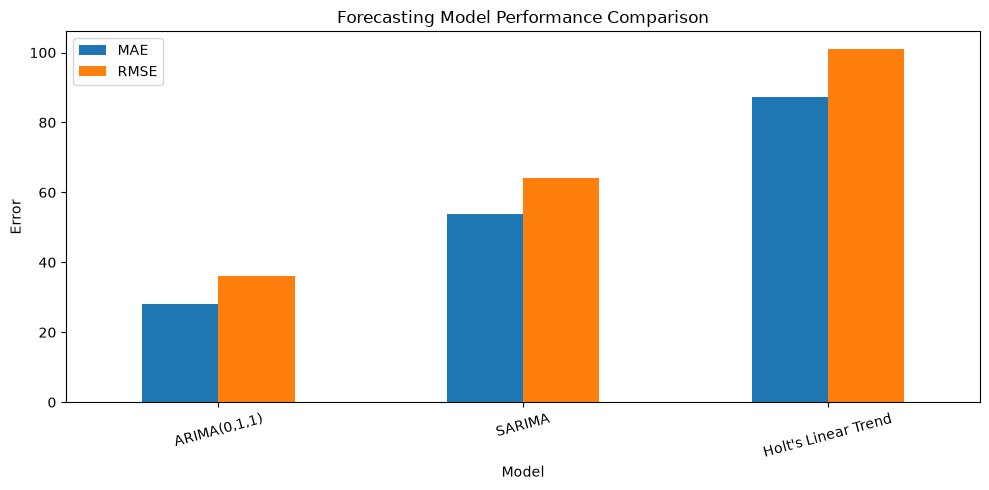

In [63]:
final_results.plot(
    x='Model',
    y=['MAE', 'RMSE'],
    kind='bar',
    figsize=(10, 5)
)

plt.title("Forecasting Model Performance Comparison")
plt.ylabel("Error")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [64]:
naive_predictions = pd.Series(
    train.iloc[-1],
    index=test.index
)

naive_mae = mean_absolute_error(
    test, naive_predictions
)

naive_rmse = np.sqrt(
    mean_squared_error(test, naive_predictions)
)

print("Naive MAE:", naive_mae)
print("Naive RMSE:", naive_rmse)

Naive MAE: 35.21212121212121
Naive RMSE: 41.66169667328696


In [65]:
print("ARIMA MAE:", 28.100105)
print("Naive MAE:", naive_mae)

print("ARIMA RMSE:", 36.091664)
print("Naive RMSE:", naive_rmse)

ARIMA MAE: 28.100105
Naive MAE: 35.21212121212121
ARIMA RMSE: 36.091664
Naive RMSE: 41.66169667328696


In [66]:
final_comparison = pd.DataFrame({
    'Model': [
        'Naive Forecast',
        'ARIMA(0,1,1)',
        'SARIMA',
        "Holt's Linear Trend"
    ],
    'MAE': [
        naive_mae,
        28.100105,
        53.735994,
        87.149360
    ],
    'RMSE': [
        naive_rmse,
        36.091664,
        64.156065,
        101.015445
    ]
})

final_comparison


,Model,MAE,RMSE
0,Naive Forecast,35.212121,41.661697
1,"ARIMA(0,1,1)",28.100105,36.091664
2,SARIMA,53.735994,64.156065
3,Holt's Linear Trend,87.149360,101.015445


In [67]:
final_comparison.to_csv(
    'model_comparison.csv',
    index=False
)

In [68]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Use the complete monthly time series
ts = monthly_data.set_index('date_added')['titles_added']

# Validation settings
initial_size = int(len(ts) * 0.70)
horizon = 6
step = 6

arima_actual = []
arima_predicted = []

naive_actual = []
naive_predicted = []

# Rolling-origin validation
for start in range(initial_size, len(ts) - horizon + 1, step):

    history = ts.iloc[:start]
    actual = ts.iloc[start:start + horizon]

    # ARIMA forecast
    model = ARIMA(history, order=(0, 1, 1))
    fitted = model.fit()

    forecast = fitted.forecast(steps=horizon)

    # Naive forecast
    naive_forecast = [history.iloc[-1]] * horizon

    arima_actual.extend(actual.values)
    arima_predicted.extend(forecast.values)

    naive_actual.extend(actual.values)
    naive_predicted.extend(naive_forecast)

print("Rolling validation completed!")
print("Forecasted observations:", len(arima_actual))

C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480:

Rolling validation completed!
Forecasted observations: 48


C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480:

In [69]:
arima_mae = mean_absolute_error(
    arima_actual, arima_predicted
)

arima_rmse = np.sqrt(
    mean_squared_error(arima_actual, arima_predicted)
)

naive_mae = mean_absolute_error(
    naive_actual, naive_predicted
)

naive_rmse = np.sqrt(
    mean_squared_error(naive_actual, naive_predicted)
)

print("ARIMA Rolling MAE:", arima_mae)
print("ARIMA Rolling RMSE:", arima_rmse)

print("\nNaive Rolling MAE:", naive_mae)
print("Naive Rolling RMSE:", naive_rmse)

ARIMA Rolling MAE: 35.86029051883398
ARIMA Rolling RMSE: 43.5443607879394

Naive Rolling MAE: 34.3125
Naive Rolling RMSE: 43.034143421241694


In [70]:
rolling_results = pd.DataFrame({
    'Model': ['ARIMA(0,1,1)', 'Naive'],
    'MAE': [arima_mae, naive_mae],
    'RMSE': [arima_rmse, naive_rmse]
})

print(rolling_results)

          Model        MAE       RMSE
0  ARIMA(0,1,1)  35.860291  43.544361
1         Naive  34.312500  43.034143


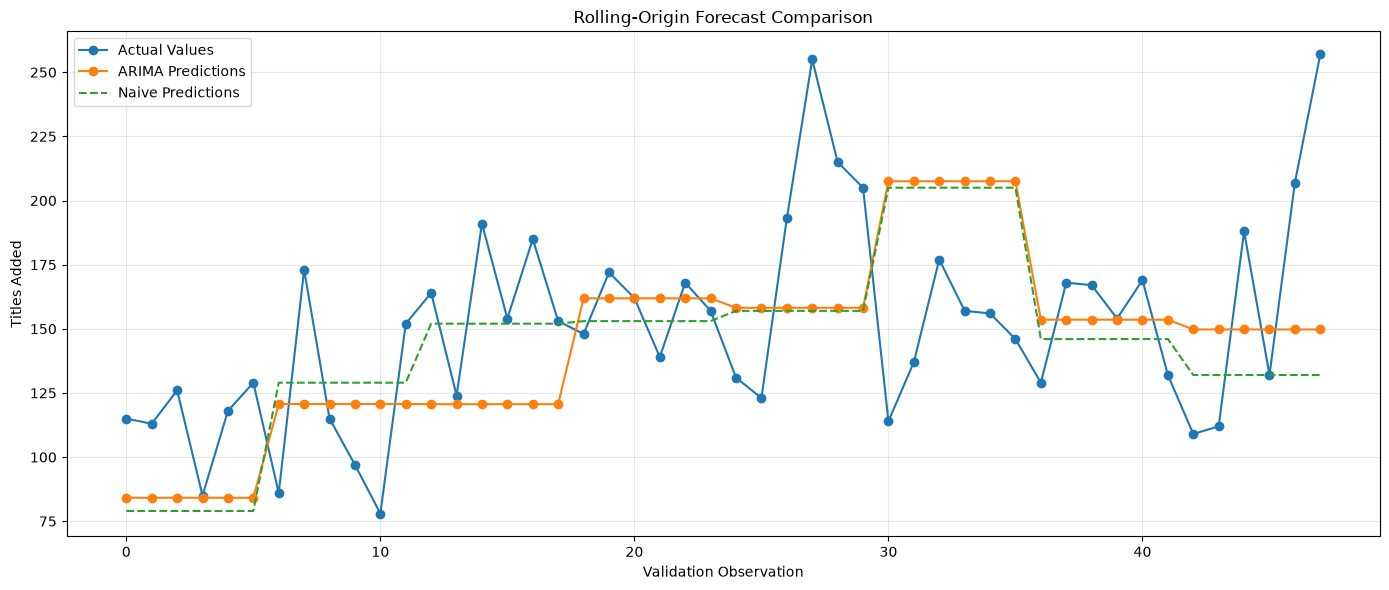

In [71]:
plt.figure(figsize=(14, 6))

plt.plot(
    arima_actual,
    label='Actual Values',
    marker='o'
)

plt.plot(
    arima_predicted,
    label='ARIMA Predictions',
    marker='o'
)

plt.plot(
    naive_predicted,
    label='Naive Predictions',
    linestyle='--'
)

plt.title("Rolling-Origin Forecast Comparison")
plt.xlabel("Validation Observation")
plt.ylabel("Titles Added")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [72]:
final_model = ARIMA(ts, order=(0, 1, 1))

final_fit = final_model.fit()

print(final_fit.summary())

                               SARIMAX Results                                
Dep. Variable:           titles_added   No. Observations:                  165
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -735.640
Date:                Wed, 04 Nov 2026   AIC                           1475.279
Time:                        23:05:25   BIC                           1481.479
Sample:                    01-01-2008   HQIC                          1477.796
                         - 09-01-2021                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5948      0.041    -14.593      0.000      -0.675      -0.515
sigma2       459.7444     24.783     18.551      0.000     411.171     508.318
Ljung-Box (L1) (Q):                   1.00   Jarque-

C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\dhars\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [73]:
future_forecast = final_fit.forecast(steps=12)
print(future_forecast)

2021-10-01    189.428593
2021-11-01    189.428593
2021-12-01    189.428593
2022-01-01    189.428593
2022-02-01    189.428593
2022-03-01    189.428593
2022-04-01    189.428593
2022-05-01    189.428593
2022-06-01    189.428593
2022-07-01    189.428593
2022-08-01    189.428593
2022-09-01    189.428593
Freq: MS, Name: predicted_mean, dtype: float64


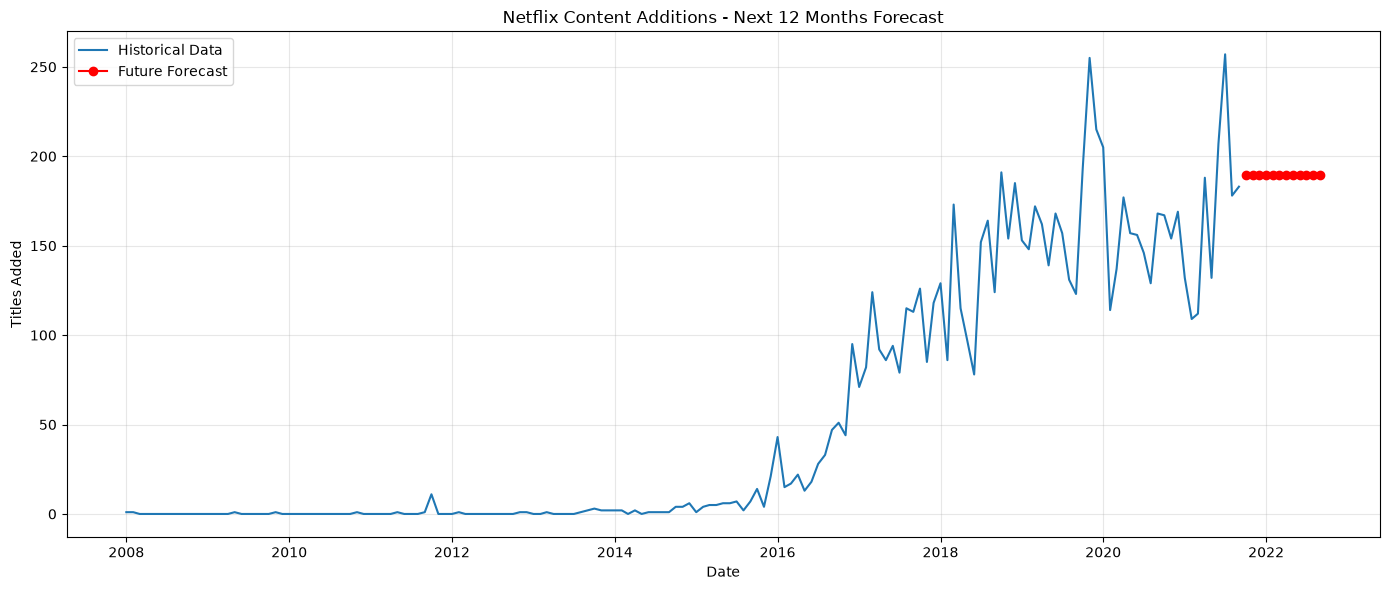

In [74]:
plt.figure(figsize=(14, 6))

plt.plot(ts, label='Historical Data')

plt.plot(
    future_forecast,
    label='Future Forecast',
    color='red',
    marker='o'
)

plt.title("Netflix Content Additions - Next 12 Months Forecast")
plt.xlabel("Date")
plt.ylabel("Titles Added")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [75]:
future_forecast.to_csv("future_forecast.csv")

In [76]:
import joblib
joblib.dump(final_fit, 'arima_model.pkl')
print("Model saved successfully!")

Model saved successfully!


In [77]:
ts.to_csv('historical_data.csv')
print("Historical data saved!")

Historical data saved!
